# Stochastic differential equations

Euler–Maruyama vs Milstein

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if device.type == 'cpu':
    torch.set_num_threads(1)
torch.manual_seed(7)
print(f'PyTorch {torch.__version__} | device: {device}')

PyTorch 2.7.1+cu126 | device: cuda


OU mean/variance: 0.9938023686408997 0.21640713512897491 | theory: 1.0 0.21333333333333337


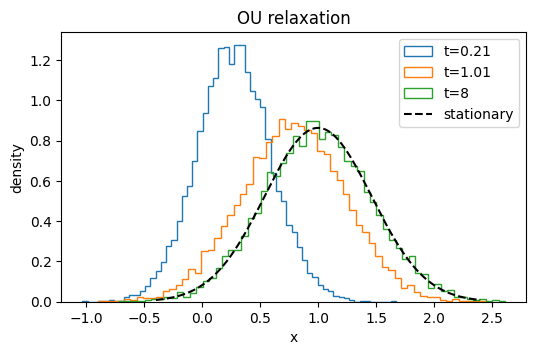

In [2]:
theta, mu, sigma, dt = 1.5, 1.0, 0.8, 0.01
n_paths, n_steps = 12_000, 800
x = torch.zeros(n_paths, device=device)
snapshots = []
for k in range(n_steps):
    x += theta*(mu-x)*dt + sigma*np.sqrt(dt)*torch.randn_like(x)
    if k in (20, 100, 799):
        snapshots.append(x.cpu().numpy().copy())
print('OU mean/variance:', float(x.mean()), float(x.var()),
      '| theory:', mu, sigma**2/(2*theta))
fig, ax = plt.subplots(figsize=(6, 3.5))
for a, label in zip(snapshots, ['t=0.21', 't=1.01', 't=8']):
    ax.hist(a, bins=60, density=True, histtype='step', label=label)
z = np.linspace(-.4, 2.4, 300); var = sigma**2/(2*theta)
ax.plot(z, np.exp(-(z-mu)**2/(2*var))/np.sqrt(2*np.pi*var), 'k--', label='stationary')
ax.set(xlabel='x', ylabel='density', title='OU relaxation'); ax.legend(); plt.show()

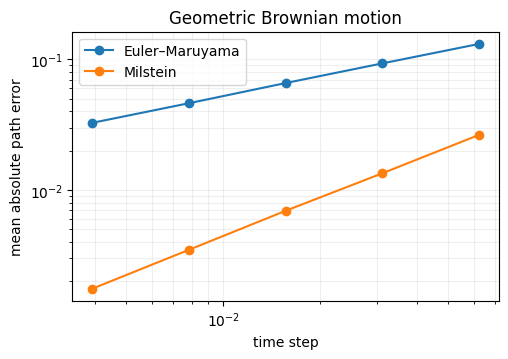

In [3]:
a, b, horizon = .4, .8, 1.0
n_paths, fine_steps = 10_000, 1024
dw_fine = torch.randn(n_paths, fine_steps, device=device) / np.sqrt(fine_steps)
exact = torch.exp((a-b*b/2)*horizon + b*dw_fine.sum(1))
results = []
for steps in [16, 32, 64, 128, 256]:
    dt = horizon/steps
    dw = dw_fine.reshape(n_paths, steps, fine_steps//steps).sum(2)
    em = torch.ones(n_paths, device=device)
    milstein = em.clone()
    for j in range(steps):
        em += a*em*dt + b*em*dw[:, j]
        milstein += a*milstein*dt + b*milstein*dw[:, j] + .5*b*b*milstein*(dw[:, j]**2-dt)
    results.append([dt, float((em-exact).abs().mean()), float((milstein-exact).abs().mean())])
results = np.array(results)
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.loglog(results[:, 0], results[:, 1], 'o-', label='Euler–Maruyama')
ax.loglog(results[:, 0], results[:, 2], 'o-', label='Milstein')
ax.set(xlabel='time step', ylabel='mean absolute path error', title='Geometric Brownian motion')
ax.legend(); ax.grid(True, which='both', alpha=.2); plt.show()